# CS 301 · Meeting 22 · Neural machines
Monday, November 16, 2026

This notebook accompanies the lecture. It runs on a **CPU** in Google Colab. Use **Runtime → Run all** for the complete experiment, or work through the sections in lecture order. No data files, account tokens, or GPU are needed.

We use a neural network through `.fit()` and `.predict()`, inspect one training step, revisit downhill search, compare hidden activations, and test what happens when a network memorizes. The last section writes the training loop in PyTorch.

**Before changing a setting, predict what will happen to training and validation performance.** The synthetic datasets have fixed seeds. The 120 test rows from the moons example stay reserved throughout this notebook. There is no test score to use for choosing settings.

The lecture results were generated with scikit-learn 1.9.1 and NumPy 2.5.4. Your installed versions are printed below. Small numerical differences across versions/platforms are possible. The notebook includes the same experiment definitions used to produce the lecture plots.

In [1]:
import warnings
import platform
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, log_loss, mean_squared_error
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 22
thread_limit = threadpool_limits(limits=1)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.12.10
NumPy: 2.5.4 | scikit-learn: 1.9.1


## 1. A neural network through `.fit()` and `.predict()`
Each observation has two numeric inputs and a binary label. We split the observations **before** learning a scaler. The scaler learns its means and scales from training rows only.

The two hidden layers each have 16 neurons. In this binary classifier, the output supplies a probability; `predict` converts that probability to a class label.

In [2]:
def moon_data():
    X, y = make_moons(n_samples=480, noise=0.24, random_state=SEED)
    X_train, X_rest, y_train, y_rest = train_test_split(
        X, y, test_size=0.5, stratify=y, random_state=SEED)
    X_valid, X_test, y_valid, y_test = train_test_split(
        X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=SEED)
    scaler = StandardScaler().fit(X_train)
    return dict(X_train=X_train, X_valid=X_valid, X_test=X_test,
                y_train=y_train, y_valid=y_valid, y_test=y_test, scaler=scaler)

In [3]:
d = moon_data()
X_train = d['scaler'].transform(d['X_train'])
X_valid = d['scaler'].transform(d['X_valid'])
y_train, y_valid = d['y_train'], d['y_valid']
print('Training:', X_train.shape, 'Validation:', X_valid.shape,
      'Reserved test:', d['X_test'].shape)

activation = 'relu'  # Try 'logistic' for sigmoid hidden neurons.
model = MLPClassifier(
    hidden_layer_sizes=(16, 16), activation=activation,
    solver='adam', learning_rate_init=0.01, batch_size=32,
    alpha=0.0001, random_state=SEED, max_iter=400,
    tol=0.0, n_iter_no_change=401, early_stopping=False)
# We deliberately stop at a fixed epoch budget, not a convergence threshold.
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    model.fit(X_train, y_train)
y_hat = model.predict(X_valid)
print('Training accuracy:', model.score(X_train, y_train))
print('Validation accuracy:', accuracy_score(y_valid, y_hat))
print('Validation log loss:', log_loss(y_valid, model.predict_proba(X_valid)))

Training: (240, 2) Validation: (120, 2) Reserved test: (120, 2)


Training accuracy: 0.975
Validation accuracy: 0.975
Validation log loss: 0.04773261892269602


In [4]:
# Inference can process one row or a batch. The weights stay fixed.
before = [w.copy() for w in model.coefs_ + model.intercepts_]
one = model.predict(X_valid[:1])
batch = model.predict(X_valid[:8])
separate = np.array([model.predict(row.reshape(1, -1))[0] for row in X_valid[:8]])
assert np.array_equal(batch, separate)
assert all(np.array_equal(a, b) for a, b in zip(before, model.coefs_ + model.intercepts_))
print('One row:', one)
print('Eight rows:', batch)
print('Same answers one at a time; parameters unchanged.')

One row: [0]
Eight rows: [0 1 1 1 1 0 0 1]
Same answers one at a time; parameters unchanged.


**Discuss:** Does a batch of eight predictions make eight training updates? Why must a single input still have shape `(1, 2)`?

## 2. One forward pass, one backward pass, one update
We use the exact tiny network from the slides. The input is `(1, 2)`, the observed label is `1`, both hidden neurons use sigmoid, and the output uses sigmoid. All biases start at zero.

For a positive label, the loss is `-log(p)`. A backward pass computes derivatives of this loss with respect to all nine parameters. It does **not** update those parameters.

In [5]:
def tiny_network():
    x = np.array([1., 2.])
    W = np.array([[.5, 0.], [-.5, 0.]])  # rows are hidden neurons
    b = np.zeros(2)
    v = np.array([1., -1.])
    c = 0.
    sigmoid = lambda z: 1/(1+np.exp(-z))
    def forward(W, b, v, c):
        h = sigmoid(W @ x + b)
        p = sigmoid(v @ h + c)
        return h, p, -np.log(p)
    h, p, loss = forward(W, b, v, c)
    dc = p - 1
    dv = dc * h
    db = dc * v * h * (1-h)
    dW = np.outer(db, x)
    eta = .5
    after = forward(W-eta*dW, b-eta*db, v-eta*dv, c-eta*dc)
    # Check every analytic derivative against a central finite difference.
    theta = np.r_[W.ravel(), b, v, c]
    analytic = np.r_[dW.ravel(), db, dv, dc]
    def objective(t): return forward(t[:4].reshape(2, 2), t[4:6], t[6:8], t[8])[2]
    numeric = np.array([(objective(theta+np.eye(9)[i]*1e-6)-objective(theta-np.eye(9)[i]*1e-6))/2e-6 for i in range(9)])
    assert np.allclose(analytic, numeric, rtol=1e-5, atol=1e-7)
    assert after[2] < loss
    return dict(x=x.tolist(), W=W.tolist(), b=b.tolist(), v=v.tolist(), c=c,
        h=h.tolist(), p=float(p), loss=float(loss), dW=dW.tolist(), db=db.tolist(),
        dv=dv.tolist(), dc=float(dc), eta=eta, after_p=float(after[1]), after_loss=float(after[2]))

In [6]:
tiny = tiny_network()
print('Hidden outputs:', np.round(tiny['h'], 6))
print('Output probability:', round(tiny['p'], 6))
print('Loss:', round(tiny['loss'], 6))
print('Gradient of the first weight:', round(tiny['dW'][0][0], 6))
print('Updated first weight:', tiny['W'][0][0] - tiny['eta'] * tiny['dW'][0][0])
print('After updating all parameters: p =', round(tiny['after_p'], 6),
      ', loss =', round(tiny['after_loss'], 6))
print('All gradients passed a central finite-difference check.')

Hidden outputs: [0.622459 0.377541]
Output probability: 0.560925
Loss: 0.578167
Gradient of the first weight: -0.103184
Updated first weight: 0.5515920783584402
After updating all parameters: p = 0.673412 , loss = 0.395398
All gradients passed a central finite-difference check.


The helper computes hidden gradients using the chain rule. You do not need to derive every entry today. Read the signs: a negative derivative says a sufficiently small increase in that parameter lowers the loss at the current point.

**Discuss:** Why should the optimizer use gradients computed from the same old weights when it updates all the weights?

## 3. Downhill search and local minima
This is an **illustrative objective**, not the measured loss of a neural network:

\[L(u,v)=(u^2-1)^2+0.25u+0.7v^2+1.\]

Try different starts and learning rates. Contours join equal losses. The left valley is lower than the right valley. A local minimum need not be the best location in the whole plane.

Start: (-0.4, 1) Final point: [-1.02989599  0.01285218] Final loss: 0.7463243878116763
Start: (0.4, 1) Final point: [0.96714894 0.01285218] Final loss: 1.2460789828369403


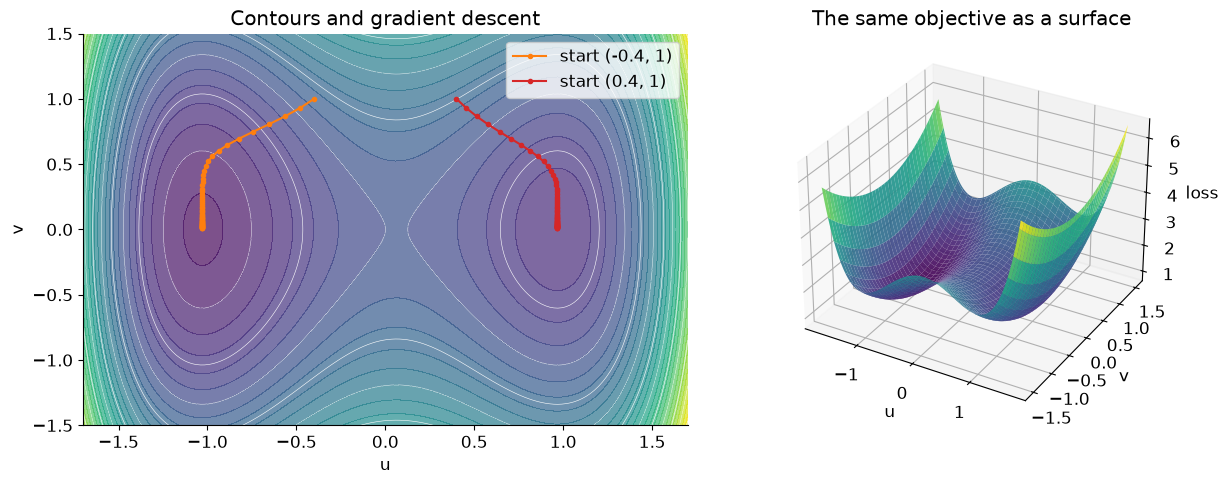

In [7]:
def landscape_loss(u, v):
    return (u*u - 1)**2 + 0.25*u + 0.7*v*v + 1

def descend(start, learning_rate=0.05, steps=60):
    point = np.array(start, dtype=float)
    path = [point.copy()]
    for _ in range(steps):
        u, v = point
        gradient = np.array([4*u*(u*u-1)+0.25, 1.4*v])
        point = point - learning_rate * gradient
        path.append(point.copy())
        if not np.isfinite(point).all() or np.max(np.abs(point)) > 20:
            break
    return np.array(path)

learning_rate = 0.05  # Try 0.01, 0.15, or 0.35.
u, v = np.meshgrid(np.linspace(-1.7, 1.7, 150), np.linspace(-1.5, 1.5, 150))
z = landscape_loss(u, v)
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(121)
ax.contourf(u, v, z, levels=30, cmap='viridis', alpha=0.7)
ax.contour(u, v, z, levels=12, colors='white', linewidths=0.4)
for start, color in [((-0.4, 1), 'tab:orange'), ((0.4, 1), 'tab:red')]:
    path = descend(start, learning_rate)
    ax.plot(path[:, 0], path[:, 1], '.-', color=color, label=f'start {start}')
    print('Start:', start, 'Final point:', path[-1],
          'Final loss:', landscape_loss(*path[-1]))
ax.set(xlim=(-1.7, 1.7), ylim=(-1.5, 1.5), xlabel='u', ylabel='v', title='Contours and gradient descent')
ax.legend()
ax3 = fig.add_subplot(122, projection='3d')
ax3.plot_surface(u, v, z, cmap='viridis', rcount=45, ccount=45, alpha=.9)
ax3.set(xlabel='u', ylabel='v', zlabel='loss', title='The same objective as a surface')
plt.tight_layout()
plt.show()

## 4. Batches, epochs, and inference
A mini-batch contributes one average loss and one optimizer update. An epoch visits every training row once. The final batch can be smaller than the others.

The 240-row training set with batch size 32 produces eight updates per epoch. Inference can also use batches, but it does not update parameters.

In [8]:
batch_size = 32  # Try 1, 32, 100, or 240.
row_order = np.random.default_rng(SEED).permutation(len(X_train))
batches = [row_order[i:i+batch_size] for i in range(0, len(row_order), batch_size)]
print('Rows in each batch:', [len(b) for b in batches])
print('Updates per training epoch:', len(batches))
assert sorted(np.concatenate(batches).tolist()) == list(range(len(X_train)))

Rows in each batch: [32, 32, 32, 32, 32, 32, 32, 16]
Updates per training epoch: 8


## 5. Hidden activations and validation
The following experiment reproduces the lecture's comparison. Both networks use two hidden layers of 16 neurons, Adam, learning rate 0.01, batch size 32, and the same data split and seed. Scikit-learn calls sigmoid `logistic`.

Every checkpoint is an actual `.fit()` run from the fixed seed with the specified epoch budget. We intentionally reach each budget; no claim of convergence is made. A fixed seed does not force identical initial weights across activation types.

Choose a metric before comparing settings. Accuracy and log loss ask different questions.

In [9]:
def classifier_result(model, X_train, y_train, X_valid, y_valid, grid):
    return dict(train_accuracy=float(model.score(X_train, y_train)),
                valid_accuracy=float(model.score(X_valid, y_valid)),
                train_log_loss=float(log_loss(y_train, model.predict_proba(X_train))),
                valid_log_loss=float(log_loss(y_valid, model.predict_proba(X_valid))),
                parameters=int(sum(a.size for a in model.coefs_ + model.intercepts_)),
                grid_probability=model.predict_proba(grid)[:, 1].tolist())

def activation_experiment():
    d = moon_data()
    X_train = d['scaler'].transform(d['X_train'])
    X_valid = d['scaler'].transform(d['X_valid'])
    gx = np.linspace(-1.8, 2.8, 55)
    gy = np.linspace(-1.3, 1.8, 41)
    xx, yy = np.meshgrid(gx, gy)
    grid = d['scaler'].transform(np.c_[xx.ravel(), yy.ravel()])
    out = dict(X_train=d['X_train'].tolist(), y_train=d['y_train'].tolist(),
               X_valid=d['X_valid'].tolist(), y_valid=d['y_valid'].tolist(),
               grid_x=gx.tolist(), grid_y=gy.tolist(), results={})
    models = {}
    for activation in ['logistic', 'relu']:
        model = MLPClassifier(hidden_layer_sizes=(16, 16), activation=activation,
            solver='adam', learning_rate_init=0.01, batch_size=32,
            alpha=0.0001, random_state=SEED, max_iter=400, tol=0.0,
            n_iter_no_change=401, early_stopping=False)
        # Refit from the same seed at each budget so every snapshot is a .fit result.
        # Reaching the fixed budget is intentional, not a convergence claim.
        curve, snapshots = [], []
        for epoch in [1, 10, 50, 100, 200, 400]:
            model.set_params(max_iter=epoch)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ConvergenceWarning)
                model.fit(X_train, d['y_train'])
            curve.append([epoch,
                log_loss(d['y_train'], model.predict_proba(X_train)),
                log_loss(d['y_valid'], model.predict_proba(X_valid))])
            snapshots.append(dict(epoch=epoch, **classifier_result(
                model, X_train, d['y_train'], X_valid, d['y_valid'], grid)))
        out['results'][activation] = dict(**classifier_result(
            model, X_train, d['y_train'], X_valid, d['y_valid'], grid),
            curve=curve, snapshots=snapshots, settings=model.get_params())
        models[activation] = model
    return out, d, models

In [10]:
activation_results, d, activation_models = activation_experiment()
for name, result in activation_results['results'].items():
    print(name, '| train accuracy:', round(result['train_accuracy'], 4),
          '| validation accuracy:', round(result['valid_accuracy'], 4),
          '| validation log loss:', round(result['valid_log_loss'], 4))

logistic | train accuracy: 0.9792 | validation accuracy: 0.9667 | validation log loss: 0.0622
relu | train accuracy: 0.975 | validation accuracy: 0.975 | validation log loss: 0.0477


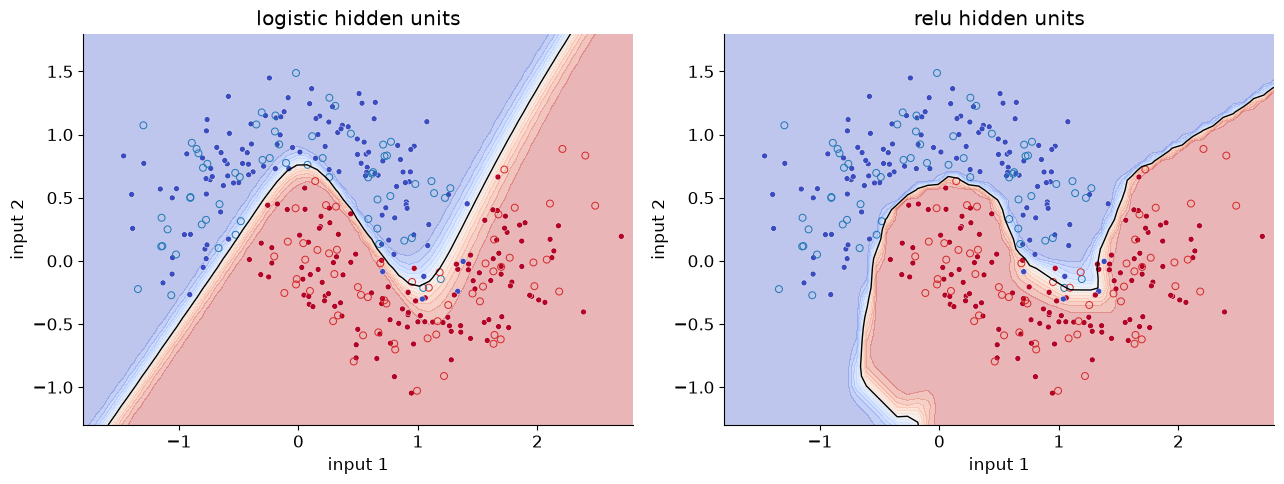

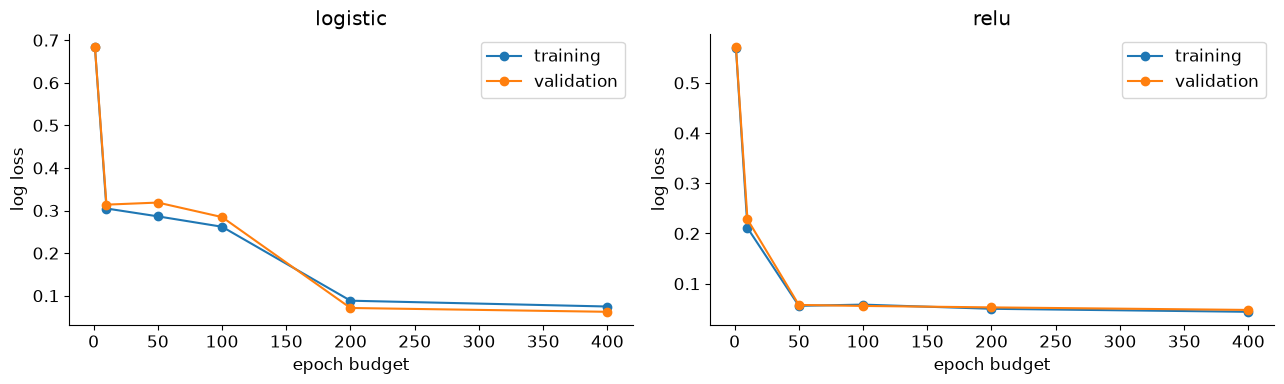

In [11]:
def plot_regions(data, result, ax, show_validation=False, title=''):
    gx, gy = data['grid_x'], data['grid_y']
    probabilities = np.asarray(result['grid_probability']).reshape(len(gy), len(gx))
    ax.contourf(gx, gy, probabilities, levels=np.linspace(0, 1, 15), cmap='coolwarm', alpha=.35)
    ax.contour(gx, gy, probabilities, levels=[.5], colors='black', linewidths=1)
    X, y = np.array(data['X_train']), np.array(data['y_train'])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', vmin=0, vmax=1, s=18, edgecolor='white', linewidth=.3)
    if show_validation:
        V, labels = np.array(data['X_valid']), np.array(data['y_valid'])
        for label, color in [(0, 'tab:blue'), (1, 'tab:red')]:
            ax.scatter(V[labels==label, 0], V[labels==label, 1], facecolor='none', edgecolor=color, s=25, linewidth=.7)
    ax.set(xlabel='input 1', ylabel='input 2', title=title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, activation in zip(axes, ['logistic', 'relu']):
    plot_regions(activation_results, activation_results['results'][activation], ax,
                 show_validation=True, title=activation+' hidden units')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, activation in zip(axes, ['logistic', 'relu']):
    curve = np.array(activation_results['results'][activation]['curve'])
    ax.plot(curve[:, 0], curve[:, 1], 'o-', label='training')
    ax.plot(curve[:, 0], curve[:, 2], 'o-', label='validation')
    ax.set(xlabel='epoch budget', ylabel='log loss', title=activation)
    ax.legend()
plt.tight_layout()
plt.show()

**Try:** Change the hidden-layer widths in the experiment function and rerun the comparison. Keep the split fixed. Record the validation metric before making another change.

**Discuss:** Can one run establish that ReLU is always better than sigmoid? Can repeatedly trying settings also overfit validation?

## 6. Random labels: fitting is not generalization
We generate coordinates independently of fair-coin labels. There is no population relationship to discover. A large network can nevertheless memorize the 80 training labels.

The fresh sample contains 400 independently generated rows and labels. Its expected accuracy is 50% for any predictor that does not see the fresh labels. A finite sample need not give exactly 50%.

Both models use ReLU, Adam, learning rate 0.01, no L2 penalty, full batches of 80, and 2000 epochs. `partial_fit` advances one epoch while preserving the optimizer state so we can inspect checkpoints.

In [12]:
def random_label_experiment():
    rng = np.random.default_rng(SEED)
    X_train, X_valid = rng.uniform(-1, 1, (80, 2)), rng.uniform(-1, 1, (400, 2))
    y_train, y_valid = rng.integers(0, 2, 80), rng.integers(0, 2, 400)
    gx, gy = np.linspace(-1, 1, 55), np.linspace(-1, 1, 41)
    xx, yy = np.meshgrid(gx, gy)
    grid = np.c_[xx.ravel(), yy.ravel()]
    out = dict(X_train=X_train.tolist(), y_train=y_train.tolist(),
        X_valid=X_valid.tolist(), y_valid=y_valid.tolist(),
        grid_x=gx.tolist(), grid_y=gy.tolist(), results={})
    models = {}
    for name, hidden in [('small', (4,)), ('large', (64, 64))]:
        model = MLPClassifier(hidden_layer_sizes=hidden, activation='relu',
            solver='adam', learning_rate_init=0.01, alpha=0,
            batch_size=80, random_state=SEED, tol=0, n_iter_no_change=2001)
        curve, snapshots = [], []
        for epoch in range(1, 2001):
            model.partial_fit(X_train, y_train, classes=np.array([0, 1]))
            if epoch == 1 or epoch % 20 == 0:
                curve.append([epoch, model.score(X_train, y_train), model.score(X_valid, y_valid)])
            if epoch in [1, 20, 100, 300, 1000, 2000]:
                snapshots.append(dict(epoch=epoch, **classifier_result(
                    model, X_train, y_train, X_valid, y_valid, grid)))
        out['results'][name] = dict(**classifier_result(model, X_train, y_train, X_valid, y_valid, grid),
            curve=curve, snapshots=snapshots, settings=model.get_params())
        models[name] = model
    return out, models

small | training accuracy: 0.5875 | fresh accuracy: 0.4775
large | training accuracy: 1.0 | fresh accuracy: 0.495


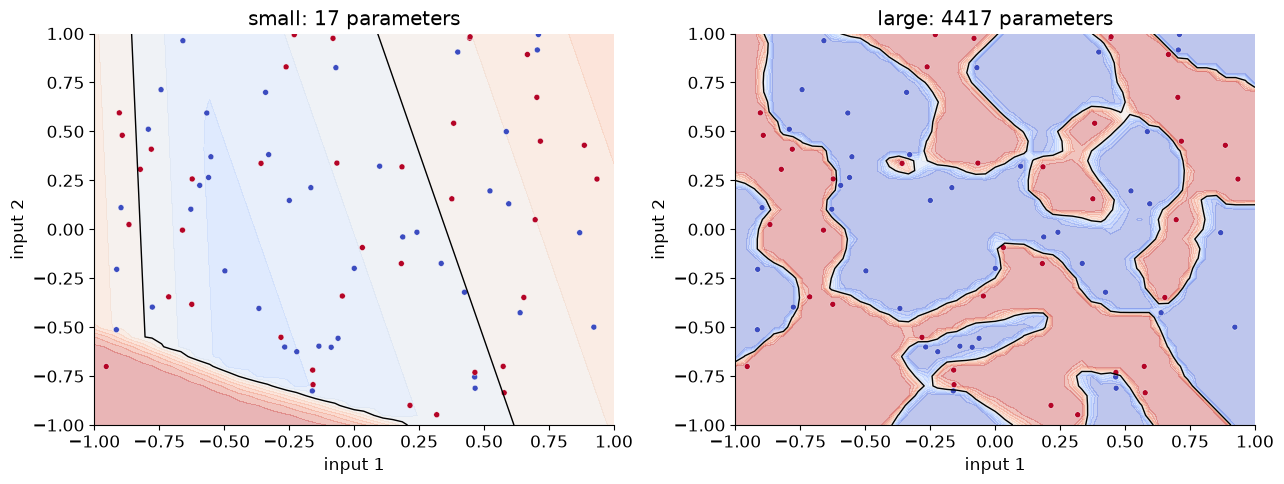

In [13]:
random_results, random_models = random_label_experiment()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ['small', 'large']):
    r = random_results['results'][name]
    plot_regions(random_results, r, ax, show_validation=False,
                 title=f"{name}: {r['parameters']} parameters")
    print(name, '| training accuracy:', r['train_accuracy'],
          '| fresh accuracy:', r['valid_accuracy'])
plt.tight_layout()
plt.show()

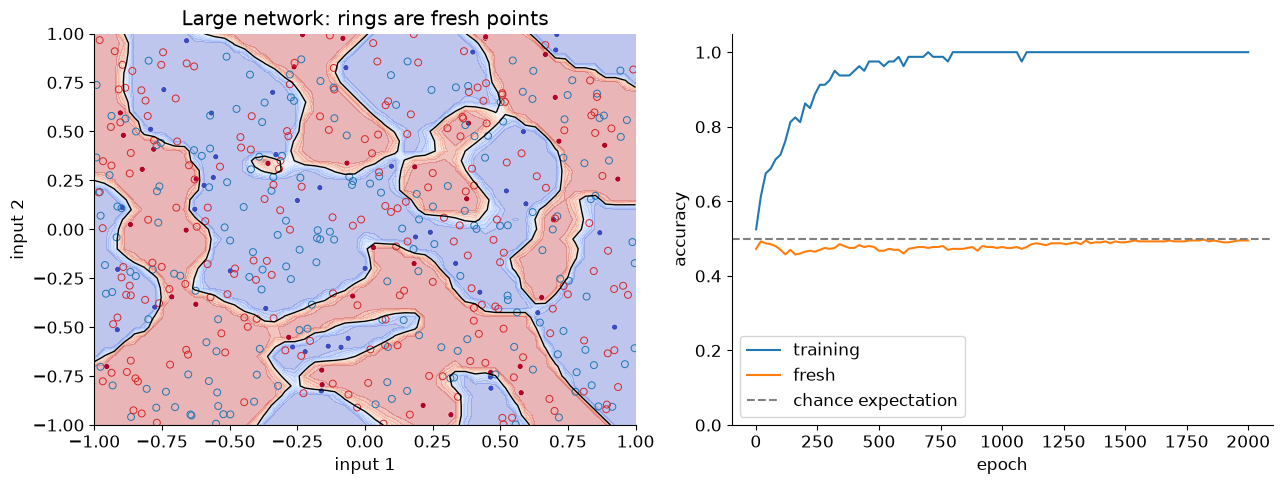

In [14]:
# Reveal the fresh points and compare accuracy throughout training.
r = random_results['results']['large']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_regions(random_results, r, axes[0], show_validation=True,
             title='Large network: rings are fresh points')
curve = np.array(r['curve'])
axes[1].plot(curve[:, 0], curve[:, 1], label='training')
axes[1].plot(curve[:, 0], curve[:, 2], label='fresh')
axes[1].axhline(.5, color='gray', linestyle='--', label='chance expectation')
axes[1].set(xlabel='epoch', ylabel='accuracy', ylim=(0, 1.05))
axes[1].legend()
plt.tight_layout()
plt.show()

**Discuss:** A larger model achieved perfect training accuracy. What evidence says it did not learn a useful population rule? Would more independently generated random-label training data create a real relationship?

## 7. Structure plus noise and early stopping
Now the target contains a real signal, `sin(3x)`, plus independent Gaussian noise with standard deviation 0.35. There are 30 training observations and 200 validation observations.

We inspect two networks and save checkpoints during training. The larger model can keep reducing training error while validation error worsens. That does not imply that every larger network performs worse than every smaller one.

In [15]:
def regression_experiment():
    rng = np.random.default_rng(SEED)
    X_train = np.sort(rng.uniform(-1, 1, 30)).reshape(-1, 1)
    X_valid = rng.uniform(-1, 1, (200, 1))
    signal = lambda X: np.sin(3 * X[:, 0])
    y_train = signal(X_train) + rng.normal(0, .35, len(X_train))
    y_valid = signal(X_valid) + rng.normal(0, .35, len(X_valid))
    grid = np.linspace(-1, 1, 300).reshape(-1, 1)
    out = dict(X_train=X_train[:, 0].tolist(), y_train=y_train.tolist(),
        X_valid=X_valid[:, 0].tolist(), y_valid=y_valid.tolist(),
        grid=grid[:, 0].tolist(), signal=signal(grid).tolist(), results={})
    models = {}
    for name, hidden in [('small', (8,)), ('large', (64, 64))]:
        model = MLPRegressor(hidden_layer_sizes=hidden, activation='relu',
            solver='adam', learning_rate_init=.01, alpha=0,
            batch_size=30, random_state=SEED, tol=0, n_iter_no_change=2501)
        curve, snapshots = [], []
        best = None
        for epoch in range(1, 2501):
            model.partial_fit(X_train, y_train)
            if epoch == 1 or epoch % 25 == 0:
                train = float(mean_squared_error(y_train, model.predict(X_train)))
                valid = float(mean_squared_error(y_valid, model.predict(X_valid)))
                curve.append([epoch, train, valid])
                snap = dict(epoch=epoch, train_mse=train, valid_mse=valid,
                            prediction=model.predict(grid).tolist())
                if best is None or valid < best['valid_mse']:
                    best = snap
                if epoch in [1, 25, 100, 300, 1000, 2500]:
                    snapshots.append(snap)
        out['results'][name] = dict(train_mse=train, valid_mse=valid,
            prediction=model.predict(grid).tolist(), curve=curve,
            snapshots=snapshots, best=best,
            parameters=int(sum(a.size for a in model.coefs_ + model.intercepts_)),
            settings=model.get_params())
        models[name] = model
    return out, models

small | final training MSE: 0.1304 | final validation MSE: 0.2734
large | final training MSE: 0.0189 | final validation MSE: 0.2566


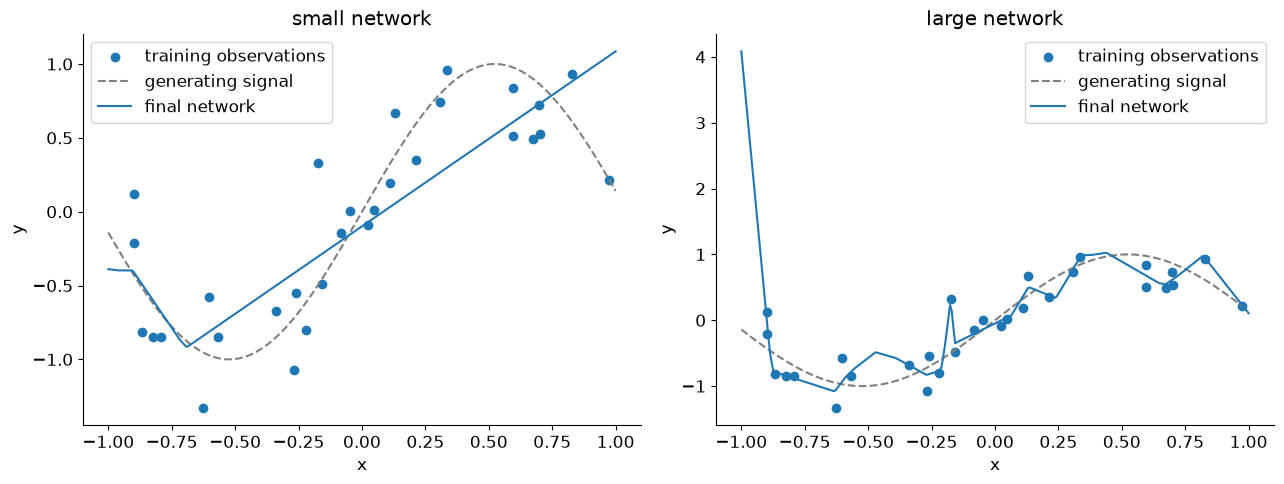

In [16]:
regression_results, regression_models = regression_experiment()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ['small', 'large']):
    r = regression_results['results'][name]
    ax.scatter(regression_results['X_train'], regression_results['y_train'], label='training observations')
    ax.plot(regression_results['grid'], regression_results['signal'], '--', color='gray', label='generating signal')
    ax.plot(regression_results['grid'], r['prediction'], label='final network')
    ax.set(xlabel='x', ylabel='y', title=name+' network')
    ax.legend()
    print(name, '| final training MSE:', round(r['train_mse'], 4),
          '| final validation MSE:', round(r['valid_mse'], 4))
plt.tight_layout()
plt.show()

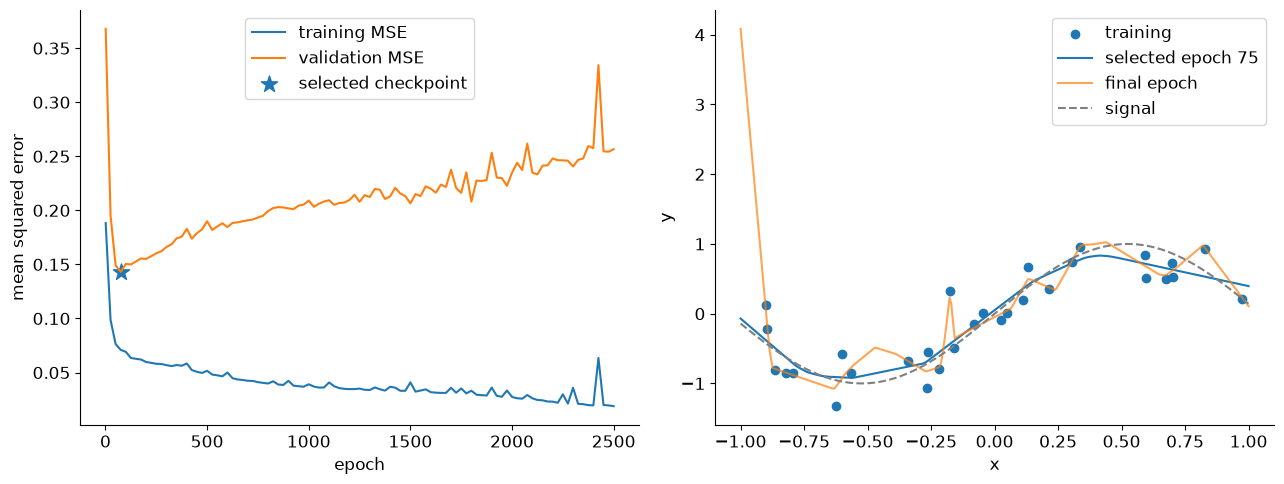

Selected checkpoint: 75 Validation MSE: 0.14312599575229495
Final validation MSE: 0.25658322404678785


In [17]:
r = regression_results['results']['large']
best = r['best']
curve = np.array(r['curve'])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(curve[:, 0], curve[:, 1], label='training MSE')
axes[0].plot(curve[:, 0], curve[:, 2], label='validation MSE')
axes[0].scatter([best['epoch']], [best['valid_mse']], marker='*', s=150, label='selected checkpoint')
axes[0].set(xlabel='epoch', ylabel='mean squared error')
axes[0].legend()
axes[1].scatter(regression_results['X_train'], regression_results['y_train'], label='training')
axes[1].plot(regression_results['grid'], best['prediction'], label=f"selected epoch {best['epoch']}")
axes[1].plot(regression_results['grid'], r['prediction'], label='final epoch', alpha=.7)
axes[1].plot(regression_results['grid'], regression_results['signal'], '--', color='gray', label='signal')
axes[1].set(xlabel='x', ylabel='y')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Selected checkpoint:', best['epoch'], 'Validation MSE:', best['valid_mse'])
print('Final validation MSE:', r['valid_mse'])

This is manual checkpoint selection using validation, illustrating the idea of early stopping. It is not a run with scikit-learn's `early_stopping=True`. The best checkpoint is the best **among those checked**. Selecting it with validation does not provide an unbiased final test estimate.

**Discuss:** Compare the final small and large models honestly. Then compare the early and late large-model checkpoints. Which comparison establishes the overfitting effect in this run?

## 8. The same training process in PyTorch
A plain PyTorch module does not supply scikit-learn's universal `.fit()` / `.predict()` interface. We write the loop explicitly.

`model.train()` chooses training behavior. It does not itself run training. `backward()` computes gradients. `optimizer.step()` updates parameters. `zero_grad()` clears gradients because PyTorch normally accumulates them.

The model below uses the same layer sizes as the scikit-learn example, but different library initialization and implementation mean it is **not an identical run**. Its last layer returns a score, or logit. `BCEWithLogitsLoss` combines sigmoid and binary cross-entropy internally.

In [18]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
torch.set_num_threads(1)
torch.manual_seed(SEED)
print('PyTorch:', torch.__version__)

X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
generator = torch.Generator().manual_seed(SEED)
loader = DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=32,
                    shuffle=True, generator=generator)
torch_model = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 16), nn.ReLU(),
    nn.Linear(16, 1))
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.01)

PyTorch: 2.15.0+cpu


First epoch loss: 0.6289036512374878
Final epoch loss: 0.05271018488953511


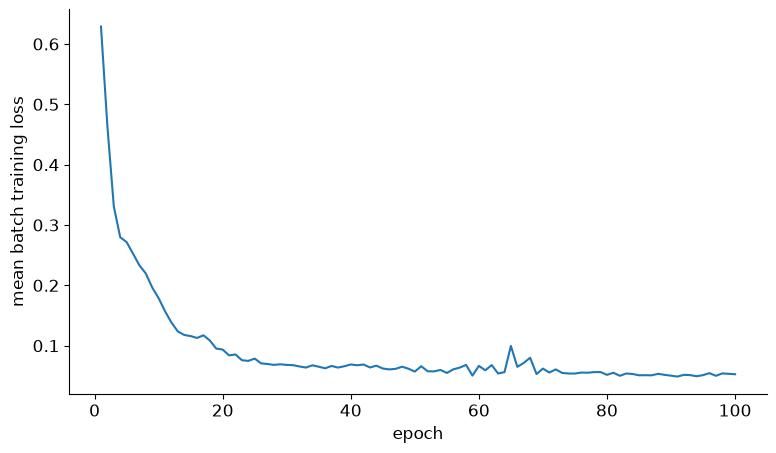

In [19]:
torch_losses = []
for epoch in range(100):
    torch_model.train()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        logits = torch_model(X_batch)          # forward
        loss = loss_fn(logits, y_batch)
        loss.backward()                       # gradients
        optimizer.step()                      # parameter update
        total_loss += loss.item() * len(X_batch)
    torch_losses.append(total_loss / len(X_tensor))
print('First epoch loss:', torch_losses[0])
print('Final epoch loss:', torch_losses[-1])
plt.plot(np.arange(1, 101), torch_losses)
plt.xlabel('epoch')
plt.ylabel('mean batch training loss')
plt.show()

In [20]:
torch_model.eval()
X_new = torch.tensor(X_valid, dtype=torch.float32)
before = [parameter.detach().clone() for parameter in torch_model.parameters()]
with torch.inference_mode():
    logits = torch_model(X_new)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).to(torch.int64)
    one_at_a_time = torch.cat([torch_model(row[None, :]) for row in X_new])
assert torch.allclose(logits, one_at_a_time, atol=1e-5)
assert all(torch.equal(a, b) for a, b in zip(before, torch_model.parameters()))
print('Validation accuracy:', accuracy_score(y_valid, predictions.numpy().ravel()))
print('Inference leaves parameters unchanged.')

Validation accuracy: 0.9833333333333333
Inference leaves parameters unchanged.


`eval()` selects evaluation behavior for layers such as dropout and batch normalization. `inference_mode()` disables gradient recording and related overhead. Our simple model has neither dropout nor batch normalization, but the distinction is useful.

The next optional cell checks PyTorch's automatic gradients against the tiny network's numerical example from the lecture.

In [21]:
# Optional: automatic differentiation reproduces the tiny network gradients.
W = torch.tensor(tiny['W'], dtype=torch.float64, requires_grad=True)
b = torch.tensor(tiny['b'], dtype=torch.float64, requires_grad=True)
v = torch.tensor(tiny['v'], dtype=torch.float64, requires_grad=True)
c = torch.tensor(tiny['c'], dtype=torch.float64, requires_grad=True)
x = torch.tensor(tiny['x'], dtype=torch.float64)
h = torch.sigmoid(W @ x + b)
score = v @ h + c
loss = nn.functional.binary_cross_entropy_with_logits(score, torch.tensor(1., dtype=torch.float64))
loss.backward()
assert np.allclose(W.grad.numpy(), tiny['dW'])
assert np.allclose(b.grad.numpy(), tiny['db'])
assert np.allclose(v.grad.numpy(), tiny['dv'])
assert np.isclose(c.grad.item(), tiny['dc'])
print('PyTorch and the lecture gradients agree for all nine parameters.')

PyTorch and the lecture gradients agree for all nine parameters.


## Review
1. What does backpropagation produce, and what changes the weights?
2. Why does predicting a batch not count as training?
3. What did the random-label experiment show about training accuracy?
4. Why should the test set stay out of hyperparameter and checkpoint selection?

<details><summary>Suggested answers</summary>

1. Backpropagation computes gradients. The optimizer changes the parameters.
2. Inference uses learned parameters without backward computation or updates.
3. Perfect training accuracy can come from memorization and need not generalize.
4. Using test results to select choices would make the test part of model selection and undermine its role as a final independent evaluation.

</details>

## Sources
- [scikit-learn neural networks](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)
- [MLPClassifier API](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)
- [MLPRegressor API](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)
- [PyTorch optimization loop](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)

All datasets in this notebook are synthetic and generated here. The landscape is illustrative. The reported empirical metrics are computed by the cells above.